# 03 · Signatures — Raghavan 2021 PDAC

Renders the three developmental-module signature UMAPs on the house linear layout. **RAW** `score_genes`
scores are shown in the deliverables (graph-smoothing aids the analysis in 02 but misleads as a deliverable).
Non-branching case → Gast/pSom co-vary at the origin, both inversely graded against Crest toward the terminus.

In [ ]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = os.path.join(sys.exec_prefix, 'lib', 'R')  # scFates PPT -> rpy2 -> r-mgcv (conda prefix)
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad')); print('loaded', adata.shape)
print('raw signature means:', {m:round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

loaded (7758, 16784)
raw signature means: {'Gast': -0.011, 'pSom': 0.072, 'Crest': -0.024}


### Signature UMAPs (raw scores) + external colorbars — house 3.5×1.5, shared left-origin orientation

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


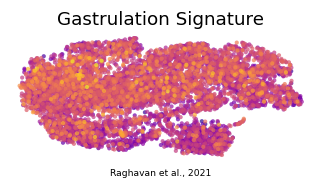

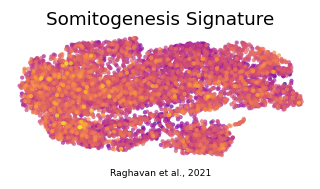

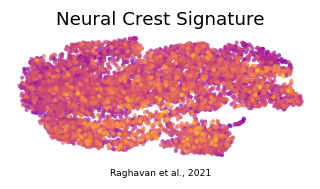

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight'); plt.show()
    lo,hi = float(adata.obs[m].min()), float(adata.obs[m].max()); ticks = np.round(np.linspace(lo,hi,5),2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight'); plt.close(fcb)
    print('saved', f'{m}_signature.pdf + colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out,'signatures.h5ad')); print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7758, 16784)
